# Introduction to Matplotlib

**Seong Cho** · ACME Python Essentials, Lab 5

**Lab objective:** introduce techniques for visualizing data in 1, 2, and 3 dimensions with Matplotlib, the most commonly used data visualization library in Python.

<sub>Lab specification from the *Python Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
%matplotlib inline
import numpy as np
from matplotlib import pyplot as plt

## Line Plots

The quickest way to visualize a 1-D array is a *line plot*. `plt.plot(y)` creates a figure and draws straight lines connecting the entries of `y`, using the array index as the $x$-axis; `plt.show()` displays the figure. Like `np` for NumPy, `plt` is the standard alias for `matplotlib.pyplot` (Matplotlib, like NumPy, is not part of the standard library but is included in most Python distributions).

[25 16  9  4  1  0  1  4  9 16 25]


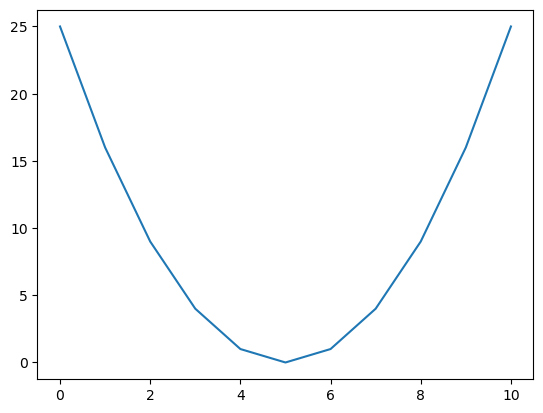

In [2]:
y = np.arange(-5, 6)**2
print(y)
plt.plot(y)         # Draw the line plot.
plt.show()          # Reveal the resulting plot.

## Problem 1: Variance of row means

> **Problem 1.** NumPy's `random` module has tools for sampling from probability distributions. For instance, `np.random.normal()` draws samples from the normal (Gaussian) distribution. The `size` parameter specifies the shape of the resulting array.
>
> ```python
> np.random.normal(size=(2,3))    # Get a 2x3 array of samples.
> ```
>
> Write a function that accepts an integer $n$ as input.
> 1. Use `np.random.normal()` to create an $n \times n$ array of values randomly sampled from the standard normal distribution.
> 2. Compute the mean of each row of the array.
>    (Hint: Use `np.mean()` and specify the `axis` keyword argument.)
> 3. Return the variance of these means.
>    (Hint: Use `np.var()` to calculate the variance).
>
> Define another function that creates an array of the results of the first function with inputs $n = 100, 200, \ldots, 1000$. Plot (and show) the resulting array.

In [3]:
def var_of_means(n):
    """Construct a random matrix A with values drawn from the standard normal
    distribution. Calculate the mean value of each row, then calculate the
    variance of these means. Return the variance.

    Parameters:
        n (int): The number of rows and columns in the matrix A.

    Returns:
        (float) The variance of the means of each row.
    """
    A = np.random.normal(size=(n,n))
    m = np.mean(A, axis=1)
    return np.var(m)

def prob1():
    """Create an array of the results of var_of_means() with inputs
    n = 100, 200, ..., 1000. Plot and show the resulting array.
    """
    ar = np.array([])
    for i in range(100, 1001, 100):
        ar = np.append(ar, var_of_means(i))
    plt.plot(ar)
    plt.show()

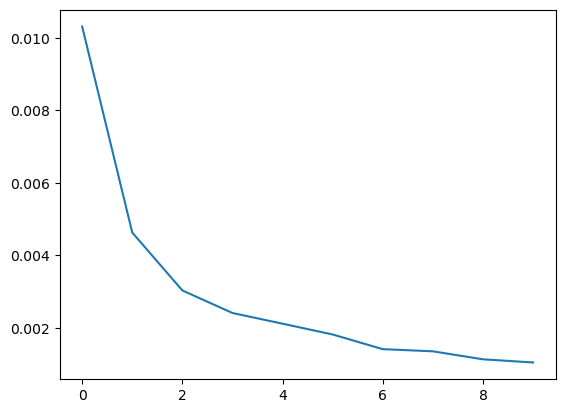

In [4]:
prob1()     # Each row mean has variance 1/n, so the curve decays like 1/n.

## Specifying a Domain

To make the $x$-axis match the function, define a domain array `x`, compute `y = f(x)`, and call `plt.plot(x, y)`, which draws lines between consecutive points `(x[i], y[i])`. For a smooth curve use `np.linspace()`, which (unlike `np.arange()`, where the *spacing* is specified) returns a specified *number* of evenly spaced values, including both endpoints.

Subsequent calls to `plt.plot()` modify the same figure until `plt.show()` displays it and resets the system.

[ 0.         10.66666667 21.33333333 32.        ]


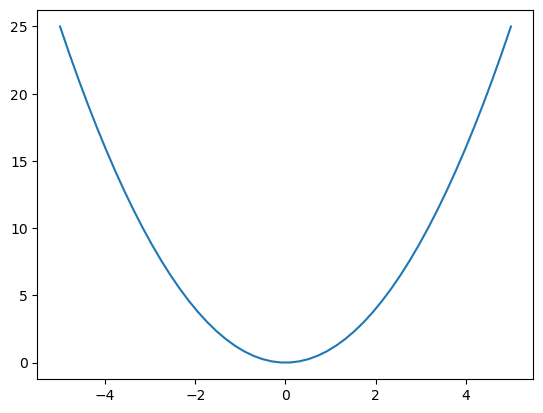

In [5]:
print(np.linspace(0, 32, 4))
x = np.linspace(-5, 5, 50)
plt.plot(x, x**2)
plt.show()

> **Note.** Plotting can seem a little mystical because the plot doesn't appear until `plt.show()` is executed. Matplotlib's *interactive mode* shows the plot being built one piece at a time — `plt.ion()` turns it on and `plt.ioff()` off — which is very useful for quick experimentation. Use interactive mode only with IPython; in a non-interactive setting it may freeze the window or cause other problems.
>
> ```text
> In [3]: plt.ion()
> In [4]: x = np.linspace(1, 4, 100)
> In [5]: plt.plot(x, np.log(x))
> In [6]: plt.plot(x, np.exp(x))
> In [7]: plt.clf()        # Clear the figure,
> In [8]: plt.ioff()       # then turn interactive mode off.
> ```
>
> (In this notebook, the inline backend draws each figure at the end of its cell, so the problem functions below that call `plt.ion()` and never `plt.show()` still display.)

## Problem 2: sin, cos, and arctan

> **Problem 2.** Write a function that plots the functions $\sin(x)$, $\cos(x)$, and $\arctan(x)$ on the domain $[-2\pi, 2\pi]$ (use `np.pi` for $\pi$). Make sure the domain is refined enough to produce a figure with good resolution.

In [6]:
def prob2():
    """Plot the functions sin(x), cos(x), and arctan(x) on the domain
    [-2pi, 2pi]. Make sure the domain is refined enough to produce a figure
    with good resolution.
    """
    plt.ion()
    x = np.linspace(-2*np.pi, 2*np.pi, 100)
    plt.plot(x, np.sin(x))
    plt.plot(x, np.cos(x))
    plt.plot(x, np.arctan(x))

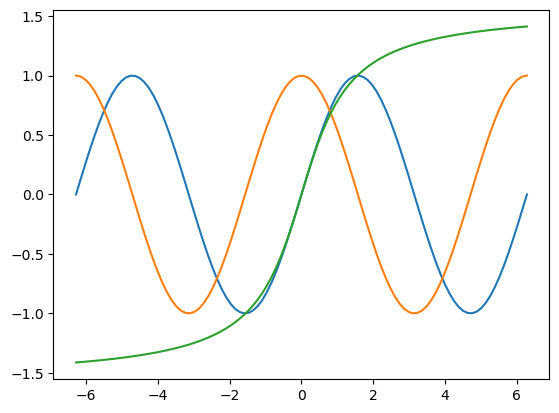

In [7]:
prob2()

## Plot Customization

A third string argument to `plt.plot()` sets the color and/or line style:

| Key | Color | | Key | Style |
|---|---|---|---|---|
| `'b'` | blue | | `'-'` | solid line |
| `'g'` | green | | `'--'` | dashed line |
| `'r'` | red | | `'-.'` | dash-dot line |
| `'c'` | cyan | | `':'` | dotted line |
| `'k'` | black | | `'o'` | circle marker |

Other `plt` functions customize the figure: `legend()` (uses the `label` argument of `plt.plot()`), `title()`, `xlim()` / `ylim()`, and `xlabel()` / `ylabel()`.

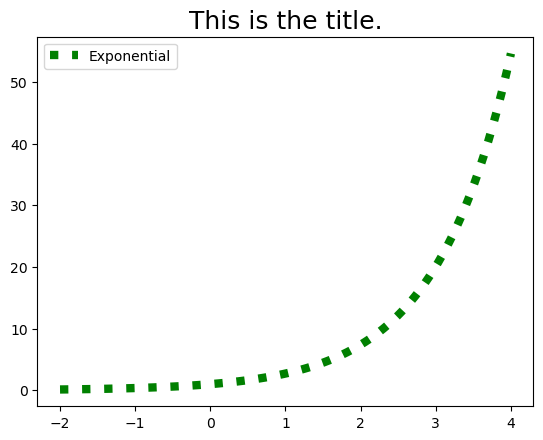

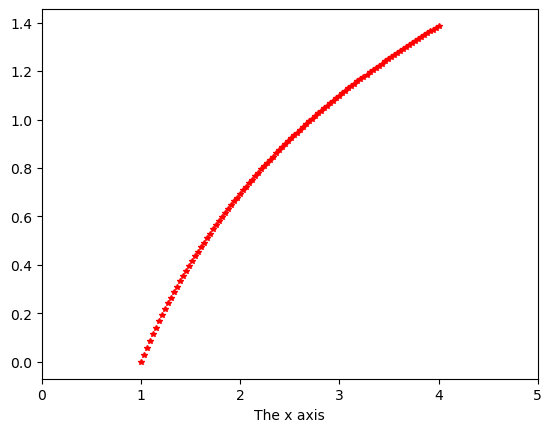

In [8]:
x1 = np.linspace(-2, 4, 100)
plt.plot(x1, np.exp(x1), 'g:', linewidth=6, label="Exponential")
plt.title("This is the title.", fontsize=18)
plt.legend(loc="upper left")
plt.show()

x2 = np.linspace(1, 4, 100)
plt.plot(x2, np.log(x2), 'r*', markersize=4)
plt.xlim(0, 5)                  # Set the visible limits of the x axis.
plt.xlabel("The x axis")
plt.show()

## Problem 3: A discontinuous curve

> **Problem 3.** Write a function to plot the curve $f(x) = \frac{1}{x-1}$ on the domain $[-2, 6]$.
> 1. Although $f(x)$ has a discontinuity at $x = 1$, a single call to `plt.plot()` in the usual way will make the curve look continuous. Split up the domain into $[-2, 1)$ and $(1, 6]$. Plot the two sides of the curve separately so that the graph looks discontinuous at $x = 1$.
> 2. Plot both curves with a dashed magenta line. Set the keyword argument `linewidth` (or `lw`) of `plt.plot()` to 4 to make the line a little thicker than the default setting.
> 3. Use `plt.xlim()` and `plt.ylim()` to change the range of the $x$-axis to $[-2, 6]$ and the range of the $y$-axis to $[-6, 6]$.
>
> The plot should resemble the figure [in the spec].

In [9]:
def prob3():
    """Plot the curve f(x) = 1/(x-1) on the domain [-2,6].
        1. Split the domain so that the curve looks discontinuous.
        2. Plot both curves with a thick, dashed magenta line.
        3. Set the range of the x-axis to [-2,6] and the range of the
           y-axis to [-6,6].
    """
    plt.ion()
    x1 = np.linspace(-2, 0.99, 50)
    x2 = np.linspace(1.01, 6, 50)
    y1 = 1/(x1-1)
    y2 = 1/(x2-1)
    plt.plot(x1,y1, 'm--', linewidth=4)
    plt.plot(x2,y2, 'm--', linewidth=4)
    plt.xlim(-2, 6)
    plt.ylim(-6, 6)

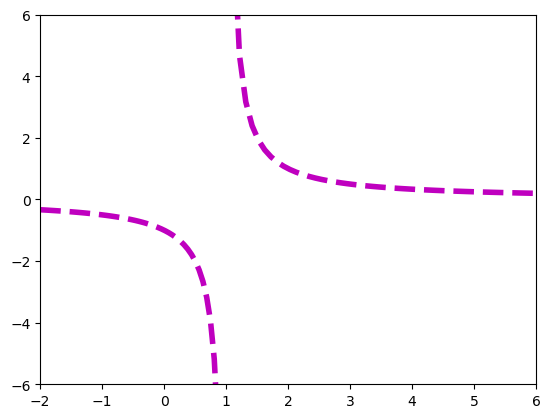

In [10]:
prob3()

## Figures, Axes, and Subplots

The window `plt.show()` reveals is a *figure* (`plt.Figure`); a space on it where a plot is drawn is an *axes* (`plt.Axes`). A figure can have several axes, and a program several figures.

| Function | Description |
|---|---|
| `axes()` | Add an axes to the current figure |
| `figure()` | Create a new figure or grab an existing figure |
| `gca()` / `gcf()` | Get the current axes / figure |
| `subplot()` | Add a single subplot to the current figure |
| `subplots()` | Create a figure and add several subplots to it |

`plt.subplot(nrows, ncols, plot_number)` creates an axes in a grid of non-overlapping subplots, numbered left to right, top to bottom. If the inputs are all integers the commas can be omitted: `plt.subplot(3,2,2)` is `plt.subplot(322)`.

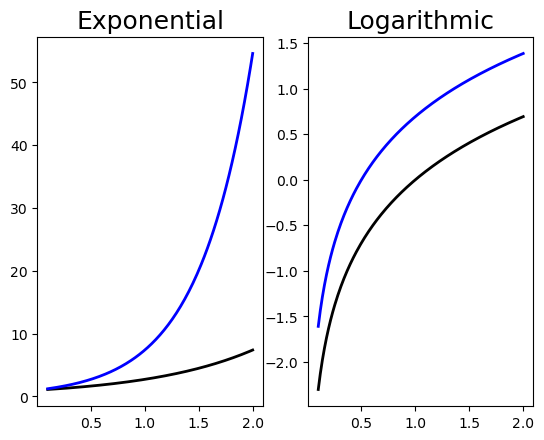

In [11]:
x = np.linspace(.1, 2, 200)
ax1 = plt.subplot(121)                  # The left half of the figure.
ax1.plot(x, np.exp(x), 'k', lw=2)
ax1.plot(x, np.exp(2*x), 'b', lw=2)
plt.title("Exponential", fontsize=18)

ax2 = plt.subplot(122)                  # The right half.
ax2.plot(x, np.log(x), 'k', lw=2)
ax2.plot(x, np.log(2*x), 'b', lw=2)
ax2.set_title("Logarithmic", fontsize=18)
plt.show()

> **Note.** Plotting functions such as `plt.plot()` are shortcuts for calling a method on the current axes of the current figure. `plt.subplot()` changes the current axes and `plt.figure()` the current figure. Three equivalent ways to make a figure with two subplots:
>
> ```python
> x = np.linspace(-5, 5, 100)
> # 1. Use plt.subplot() to switch the current axes.
> plt.subplot(121)
> plt.plot(x, 2*x)
> plt.subplot(122)
> plt.plot(x, x**2)
> # 2. Use plt.subplot() to explicitly grab the two subplot axes.
> ax1 = plt.subplot(121)
> ax1.plot(x, 2*x)
> ax2 = plt.subplot(122)
> ax2.plot(x, x**2)
> # 3. Use plt.subplots() to get the figure and all subplots simultaneously.
> fig, axes = plt.subplots(1, 2)
> axes[0].plot(x, 2*x)
> axes[1].plot(x, x**2)
> ```

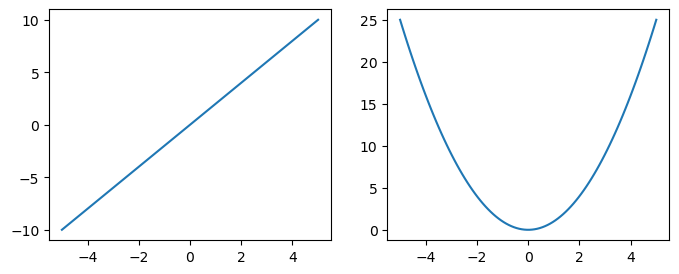

In [12]:
x = np.linspace(-5, 5, 100)
fig, axes = plt.subplots(1, 2, figsize=(8, 3))      # Strategy 3.
axes[0].plot(x, 2*x)
axes[1].plot(x, x**2)
plt.show()

## Problem 4: Sine functions in subplots

> **Problem 4.** Write a function that plots the functions $\sin(x)$, $\sin(2x)$, $2\sin(x)$, and $2\sin(2x)$ on the domain $[0, 2\pi]$, each in a separate subplot of a single figure.
> 1. Arrange the plots in a $2 \times 2$ grid of subplots.
> 2. Set the limits of each subplot to $[0, 2\pi] \times [-2, 2]$.
>    (Hint: Consider using `plt.axis([xmin, xmax, ymin, ymax])` instead of `plt.xlim()` and `plt.ylim()` to set all boundaries simultaneously.)
> 3. Use `plt.title()` or `ax.set_title()` to give each subplot an appropriate title.
> 4. Use `plt.suptitle()` or `fig.suptitle()` to give the overall figure a title.
> 5. Use the following colors and line styles.
>
>    $\sin(x)$: green solid line. $\sin(2x)$: red dashed line.
>    $2\sin(x)$: blue dashed line. $2\sin(2x)$: magenta dotted line.

In [13]:
def prob4():
    """Plot the functions sin(x), sin(2x), 2sin(x), and 2sin(2x) on the
    domain [0, 2pi].
        1. Arrange the plots in a square grid of four subplots.
        2. Set the limits of each subplot to [0, 2pi]x[-2, 2].
        3. Give each subplot an appropriate title.
        4. Give the overall figure a title.
        5. Use the following line colors and styles.
              sin(x): green solid line.
             sin(2x): red dashed line.
             2sin(x): blue dashed line.
            2sin(2x): magenta dotted line.
    """
    plt.ion()
    lim = [0, 2*np.pi, -2, 2]
    x = np.linspace(0, 2*np.pi, 100)

    ax1 = plt.subplot(221)
    ax1.plot(x, np.sin(x), 'g')
    ax1.set_title("sin(x)")
    plt.axis(lim)

    ax2 = plt.subplot(222)
    ax2.plot(x, np.sin(2*x), 'r--')
    ax2.set_title("sin(2x)")
    plt.axis(lim)

    ax3 = plt.subplot(223)
    ax3.plot(x, 2*np.sin(x), 'b--')
    ax3.set_title("2sin(x)")
    plt.axis(lim)

    ax4 = plt.subplot(224)
    ax4.set_title("2sin(2x)")
    ax4.plot(x, 2*np.sin(2*x), 'm:')
    plt.axis(lim)

    plt.suptitle("Different Sine Functions")

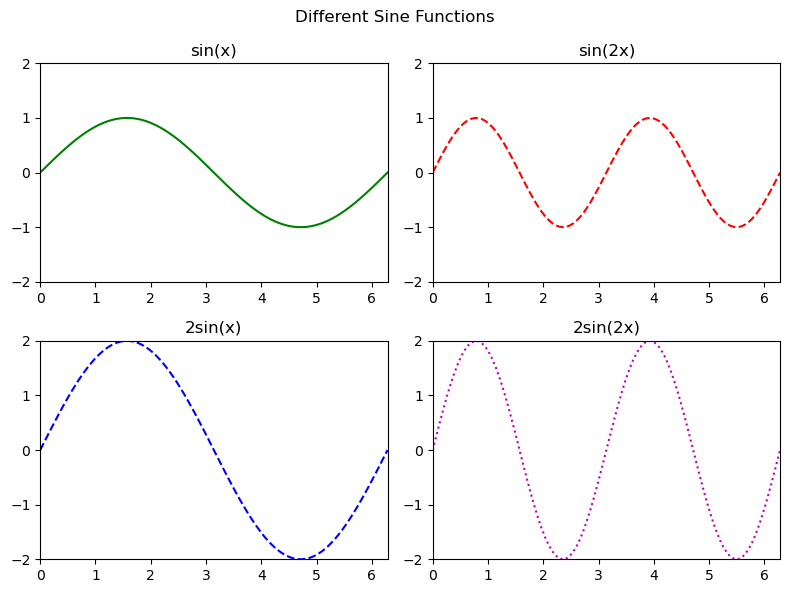

In [14]:
plt.figure(figsize=(8, 6))      # A larger figure, so the titles don't collide with tick labels.
prob4()
plt.tight_layout()

> **Achtung!** Be careful not to mix up the following functions.
> 1. `plt.axes()` creates a new place to draw on the figure, while `plt.axis()` (or `ax.axis()`) sets properties of the $x$- and $y$-axis in the current axes, such as the $x$ and $y$ limits.
> 2. `plt.subplot()` (singular) returns a single subplot belonging to the current figure, while `plt.subplots()` (plural) creates a new figure and adds a collection of subplots to it.

## Other Kinds of Plots

- A **scatter plot** plots two 1-D arrays against each other without connecting lines; it suits data that is not correlated or ordered. Use `plt.plot()` with a point marker (such as `'o'` or `'*'`), or `plt.scatter()` / `ax.scatter()`, which has slightly different arguments and syntax.
- A **histogram** groups a 1-D data set into intervals called *bins*, with bar heights giving the count in each bin; it is best for displaying distributions. Use `plt.hist()` / `ax.hist()`; `bins` gives the bin edges or the number of bins, and `range` the outer limits of the first and last bins.

Matplotlib also makes bar plots and box plots (see the Matplotlib Appendix of the manual).

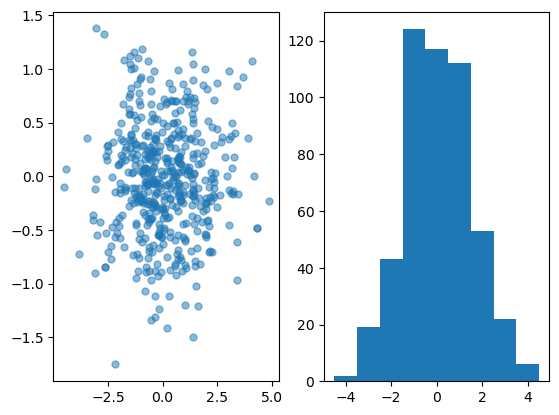

In [15]:
x = np.random.normal(scale=1.5, size=500)
y = np.random.normal(scale=0.5, size=500)

ax1 = plt.subplot(121)
ax1.plot(x, y, 'o', markersize=5, alpha=.5)         # Transparent circle markers.
ax2 = plt.subplot(122)
ax2.hist(x, bins=np.arange(-4.5, 5.5))              # Or bins=9, range=[-4.5, 4.5].
plt.show()

## Problem 5: FARS crash data

> **Problem 5.** The Fatality Analysis Reporting System (FARS) is a nationwide census that provides yearly data regarding fatal injuries suffered in motor vehicle traffic crashes. (See http://www.nhtsa.gov/FARS.) The array contained in `FARS.npy` is a small subset of the FARS database from 2010–2014. Each of the 148,206 rows in the array represents a different car crash; the columns represent the hour (in military time, as an integer), the longitude, and the latitude, in that order.
>
> Write a function to visualize the data in `FARS.npy`. Use `np.load()` to load the data, then create a single figure with two subplots:
> 1. A scatter plot of longitudes against latitudes. Because of the large number of data points, use black pixel markers (use `"k,"` as the third argument to `plt.plot()`). Label both axes using `plt.xlabel()` and `plt.ylabel()` (or `ax.set_xlabel()` and `ax.set_ylabel()`).
>    (Hint: Use `plt.axis("equal")` or `ax.set_aspect("equal")` so that the $x$- and $y$-axis are scaled the same way.)
> 2. A histogram of the hours of the day, with one bin per hour. Set the limits of the $x$-axis appropriately. Label the $x$-axis. You should be able to clearly see which hours of the day experience more traffic.

In [16]:
def prob5():
    """Visualize the data in FARS.npy. Use np.load() to load the data, then
    create a single figure with two subplots:
        1. A scatter plot of longitudes against latitudes. Because of the
            large number of data points, use black pixel markers (use "k,"
            as the third argument to plt.plot()). Label both axes.
        2. A histogram of the hours of the day, with one bin per hour.
            Label and set the limits of the x-axis.
    """
    fars = np.load("FARS.npy")
    plt.ion()

    ax1 = plt.subplot(121)
    x1 = fars[:,1]
    y1 = fars[:,2]
    ax1.plot(x1, y1, "k,")
    ax1.set_xlabel("Longitudes")
    ax1.set_ylabel("Latitudes")
    ax1.set_aspect("equal")

    ax2 = plt.subplot(122)
    x2 = fars[:,0]
    ax2.hist(x2, bins=np.arange(0,25))   # Fixed: was arange(0,24), which merged hours 22 and 23 into one bin.
    ax2.set_xlim(0, 24)                  # Added: the spec asks for x-axis limits.
    ax2.set_xlabel("Hour of the day")

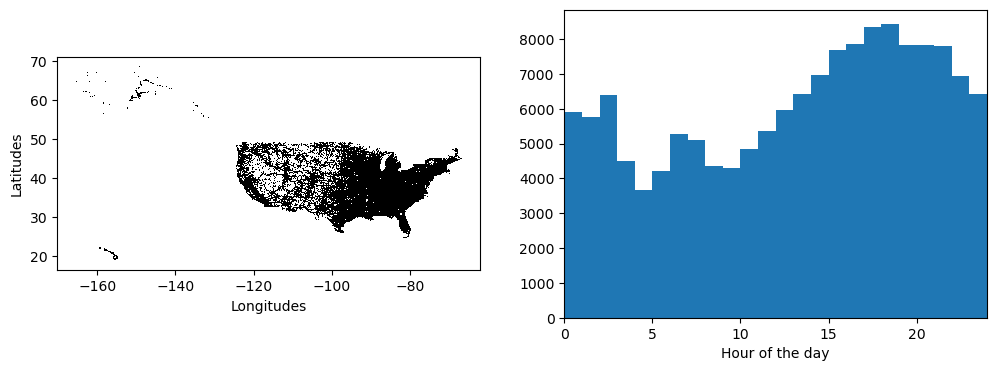

In [17]:
plt.figure(figsize=(12, 4))     # A wider figure so the map isn't squeezed.
prob5()

## Visualizing 3-D Surfaces

Visualizing a function $g: \mathbb{R}^2 \to \mathbb{R}$ takes a 2-D domain, usually built with `np.meshgrid()`: given two 1-D coordinate arrays, it returns two coordinate matrices `X` and `Y` giving the $x$- and $y$-coordinates of every point in the grid.

In [18]:
x, y = [0, 1, 2], [3, 4, 5]         # A rough domain over [0,2]x[3,5].
X, Y = np.meshgrid(x, y)
for xrow, yrow in zip(X, Y):
    print(xrow, yrow, sep='\t')

[0 1 2]	[3 3 3]
[0 1 2]	[4 4 4]
[0 1 2]	[5 5 5]


Two kinds of plots are usual on a 2-D domain:

- A **heat map** (`plt.pcolormesh()`) assigns a color to each point of the domain. Darker colors typically mean lower values, lighter colors higher.
- A **contour map** (`plt.contour()`, or `plt.contourf()` for filled contours) draws *level curves* $\{(x,y) \mid c = g(x,y)\}$. Give either the number of level curves or a list of the constants $c$. More level curves make a filled contour plot look more like the full heat map.

Each takes `cmap` for the color scheme (some of the better ones are `"viridis"`, `"magma"`, and `"coolwarm"`; full list at http://matplotlib.org/examples/color/colormaps_reference.html), and `plt.colorbar()` draws the color scale beside the plot.

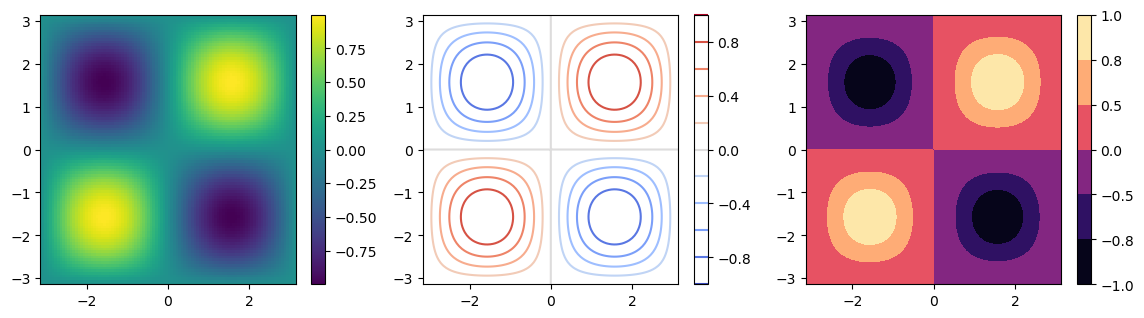

In [19]:
x = np.linspace(-np.pi, np.pi, 100)
X, Y = np.meshgrid(x, x.copy())
Z = np.sin(X) * np.sin(Y)               # g(x,y) = sin(x)sin(y).

plt.figure(figsize=(14, 3.5))
plt.subplot(131)                        # Heat map.
plt.pcolormesh(X, Y, Z, cmap="viridis")
plt.colorbar()
plt.xlim(-np.pi, np.pi)
plt.ylim(-np.pi, np.pi)

plt.subplot(132)                        # Contour map with 10 level curves.
plt.contour(X, Y, Z, 10, cmap="coolwarm")
plt.colorbar()

plt.subplot(133)                        # Filled contours at chosen levels.
plt.contourf(X, Y, Z, [-1, -.8, -.5, 0, .5, .8, 1], cmap="magma")
plt.colorbar()
plt.show()

## Problem 6: Heat map and contour map

> **Problem 6.** Write a function to plot $g(x, y) = \frac{\sin(x)\sin(y)}{xy}$ on the domain $[-2\pi, 2\pi] \times [-2\pi, 2\pi]$.
> 1. Create 2 subplots: one with a heat map of $g$, and one with a contour map of $g$. Choose an appropriate number of level curves, or specify the curves yourself.
> 2. Set the limits of each subplot to $[-2\pi, 2\pi] \times [-2\pi, 2\pi]$.
> 3. Choose a non-default color scheme.
> 4. Include the color scale bar for each subplot.

In [20]:
def prob6():
    """Plot the function f(x,y) = sin(x)sin(y)/xy on the domain
    [-2pi, 2pi]x[-2pi, 2pi].
        1. Create 2 subplots: one with a heat map of f, and one with a contour
            map of f. Choose an appropriate number of level curves, or specify
            the curves yourself.
        2. Set the limits of each subplot to [-2pi, 2pi]x[-2pi, 2pi].
        3. Choose a non-default color scheme.
        4. Add a colorbar to each subplot.
    """
    plt.ion()
    x = np.linspace(-2*np.pi, 2*np.pi, 100)
    y = x.copy()
    X, Y = np.meshgrid(x,y)
    g = (np.sin(X)*np.sin(Y))/(X*Y)
    lim = np.array([-2*np.pi, 2*np.pi, -2*np.pi, 2*np.pi])

    plt.subplot(121)
    plt.pcolormesh(X, Y, g, cmap="coolwarm")
    plt.colorbar()
    plt.axis(lim)

    plt.subplot(122)
    plt.contour(X, Y, g, 15, cmap="magma")
    plt.colorbar()
    plt.axis(lim)

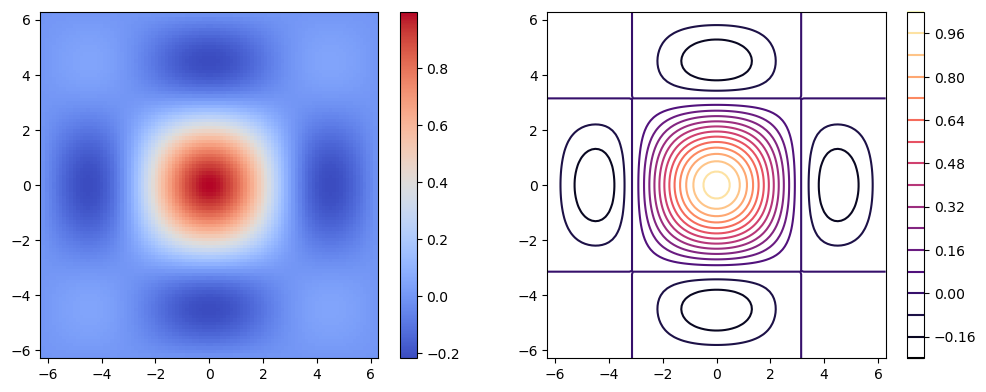

In [21]:
plt.figure(figsize=(12, 4.5))
prob6()

## Additional Material

### Further reading and tutorials

The lab recommends, as written:
- https://www.labri.fr/perso/nrougier/teaching/matplotlib/.
- https://matplotlib.org/users/pyplot_tutorial.html.
- http://www.scipy-lectures.org/intro/matplotlib/matplotlib.html.
- The Matplotlib Appendix in this manual.

### 3-D plotting

Matplotlib can also draw 3-D surfaces, here $g(x,y) = \sin(x)\sin(y)$:

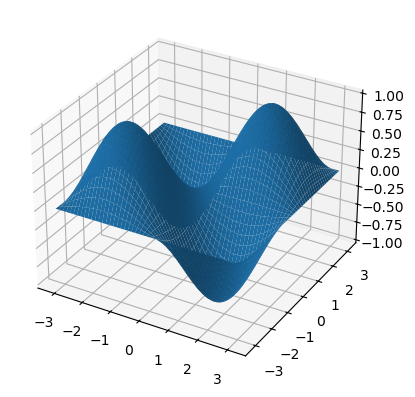

In [22]:
x = np.linspace(-np.pi, np.pi, 200)
X, Y = np.meshgrid(x, np.copy(x))
Z = np.sin(X) * np.sin(Y)

from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection='3d')
ax.plot_surface(X, Y, Z)
plt.show()

### Animations

Steps for a Matplotlib animation: (1) calculate all the data needed; (2) define a figure explicitly with `plt.figure()` and set its window boundaries; (3) draw empty objects that can be altered dynamically; (4) define a function that updates the drawing objects; (5) pass them to `matplotlib.animation.FuncAnimation()`, which takes the figure, the update function, the number of frames before repeating, and the interval (lower numbers mean faster animations). The animations play in a GUI window via `plt.show()`, so the spec's code is kept here as written rather than run:

```python
from matplotlib.animation import FuncAnimation

def sine_animation():
    # Calculate the data to be animated.
    x = np.linspace(0, 2*np.pi, 200)[:-1]
    y = np.sin(x)
    # Create a figure and set the window boundaries of the axes.
    fig = plt.figure()
    plt.xlim(0, 2*np.pi)
    plt.ylim(-1.2, 1.2)
    # Draw an empty line. The comma after 'drawing' is crucial.
    drawing, = plt.plot([],[])
    # Define a function that updates the line data.
    def update(index):
        drawing.set_data(x[:index], y[:index])
        return drawing,         # Note the comma!
    a = FuncAnimation(fig, update, frames=len(x), interval=10)
    plt.show()
```

Try this function in place of `update()` — can you explain why the animation is different?

```python
def wave(index):
    drawing.set_data(x, np.roll(y, index))
    return drawing,
```

To animate several objects at once, define each separately and have the update function return all of them (e.g. `return sin_drawing, cos_drawing,`). 3-D animations differ mainly in one extra call to set the third component; this one draws the space curve $x(\theta) = \cos(\theta)\cos(6\theta)$, $y(\theta) = \sin(\theta)\cos(6\theta)$, $z(\theta) = \frac{\theta}{10}$:

```python
def rose_animation_3D():
    theta = np.linspace(0, 2*np.pi, 200)
    x = np.cos(theta) * np.cos(6*theta)
    y = np.sin(theta) * np.cos(6*theta)
    z = theta / 10
    fig = plt.figure()
    ax = fig.gca(projection='3d')       # Make the figure 3-D.
    ax.set_xlim3d(-1.2, 1.2)            # Use ax instead of plt.
    ax.set_ylim3d(-1.2, 1.2)
    ax.set_aspect("equal")
    drawing, = ax.plot([],[],[])        # Provide 3 empty lists.
    # Update the first 2 dimensions like usual, then update the 3-D component.
    def update(index):
        drawing.set_data(x[:index], y[:index])
        drawing.set_3d_properties(z[:index])
        return drawing,
    a = FuncAnimation(fig, update, frames=len(x), interval=10, repeat=False)
    plt.show()
```